In [ ]:
# INSTALL

!pip install -q eclipse-sumo sumo-rl==1.4.5 ray==2.54.0 pettingzoo==1.23.0 lz4==4.4.5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.0/73.0 MB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 826.8/826.8 kB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.2/140.2 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.5/233.5 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.4/138.4 kB 7.0 MB/s eta 0:00:00


In [2]:
# IMPORTS / SETUP

import os
import warnings
import logging
import numpy as np
import pandas as pd
import itertools
import ray
import sumo
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

os.environ["PYTHONWARNINGS"] = "ignore::DeprecationWarning"
warnings.filterwarnings("ignore")
os.environ["SUMO_HOME"] = os.path.dirname(sumo.__file__)
logging.getLogger("ray").setLevel(logging.ERROR)
logging.getLogger("ray.rllib").setLevel(logging.CRITICAL)

from ray.rllib.algorithms.ppo import PPOConfig
from ray.rllib.algorithms.impala import ImpalaConfig
from ray.tune.registry import register_env
from ray.rllib.env.wrappers.pettingzoo_env import PettingZooEnv
import sumo_rl

class FilteredStdout:  # for colab only
    def __init__(self, original):
        self.original = original
        self.encoding = getattr(original, "encoding", "utf-8")
        self._buffer = ""

    def write(self, text):
        self._buffer += text

        while "\n" in self._buffer:
            line, self._buffer = self._buffer.split("\n", 1)

            if "Retrying in" in line:
                continue

            self.original.write(line + "\n")

    def flush(self):
        if self._buffer:
            if "Retrying in" not in self._buffer:
                self.original.write(self._buffer)
            self._buffer = ""
        self.original.flush()

    def __getattr__(self, name):
        return getattr(self.original, name)

import sys
sys.stdout = FilteredStdout(sys.stdout)
sys.stderr = FilteredStdout(sys.stderr)

In [ ]:
# CONFIG

BASE_PATH = os.path.dirname(sumo_rl.__file__)

NET_FILE = os.path.join(BASE_PATH, "nets/3x3grid/3x3Grid2lanes.net.xml")
ROUTE_FILE = os.path.join(BASE_PATH, "nets/3x3grid/routes14000.rou.xml")

ENV_NAME = "sumo_3x3"

TRAIN_SECONDS = 2000
EVAL_SECONDS = 4000
TRAIN_ITERS = 3
CURRENT_REWARD = None  # means default reward = (previous_total_waiting_time - current_total_waiting_time) / 100

In [ ]:
# ENVIRONMENT

def make_env(num_seconds, parallel=False):

    kwargs = dict(
        net_file=NET_FILE,
        route_file=ROUTE_FILE,
        use_gui=False,
        num_seconds=num_seconds,
    )

    if CURRENT_REWARD is not None:
        kwargs["reward_fn"] = CURRENT_REWARD

    if parallel:
        return sumo_rl.parallel_env(**kwargs)

    return PettingZooEnv(sumo_rl.env(**kwargs))


def init_ray():
    if ray.is_initialized():
        ray.shutdown()

    ray.init(
        ignore_reinit_error=True,
        log_to_driver=False,
        logging_level=logging.ERROR,
    )

    register_env(ENV_NAME, lambda cfg: make_env(TRAIN_SECONDS))


def map_policy(agent_id, *args, **kwargs):
    return "shared_policy"


def multiagent():
    return dict(
        policies={"shared_policy"},
        policy_mapping_fn=map_policy,
    )


# POLICIES

class RandomPolicy:
    def act(self, env, _):
        return {a: env.action_space(a).sample() for a in env.agents}


class FixedTimePolicy:
    def __init__(self, cycle=40):
        self.t = 0
        self.cycle = cycle
        self.phase = {}

    def act(self, env, _):
        if not self.phase:
            self.phase = {a: 0 for a in env.agents}

        self.t += 1

        if self.t % self.cycle == 0:
            for a in env.agents:
                n = env.action_space(a).n
                self.phase[a] = (self.phase[a] + 1) % n

        return self.phase.copy()


class RLPolicy:
    def __init__(self, algo):
        self.algo = algo

    def act(self, env, obs):
        return self.algo.compute_actions(
            {a: obs[a] for a in env.agents},
            policy_id="shared_policy",
            explore=False,
        )


def build_algo(algo, params):

    if algo == "mappo":
        base = PPOConfig()
    if algo == "impala":
        base = ImpalaConfig()

    config = (
        base
        .environment(env=ENV_NAME)
        .env_runners(
            num_env_runners=0,
            batch_mode="complete_episodes",
            # not used if batch_mode="complete_episodes"
            # rollout_fragment_length=COMMON_ENV["rollout_fragment_length"],
        )
        .training(
            lr=params.get("lr", COMMON_TRAIN["lr"]),
            gamma=COMMON_TRAIN["gamma"],
            train_batch_size=params.get("train_batch_size", COMMON_TRAIN["train_batch_size"]),
            entropy_coeff=params.get("entropy_coeff", COMMON_TRAIN["entropy_coeff"]),
            vf_loss_coeff=COMMON_TRAIN["vf_loss_coeff"],
        )
        .multi_agent(**multiagent())
        .framework("torch")
        .resources(num_gpus=0)
        .api_stack(
            enable_rl_module_and_learner=False,
            enable_env_runner_and_connector_v2=False,
        )
    )

    if algo == "mappo":
        config = config.training(
            lambda_=params.get("lambda_", PPO_PARAMS["lambda_"]),
            clip_param=params.get("clip_param", PPO_PARAMS["clip_param"]),
            num_epochs=PPO_PARAMS["num_epochs"],
        )

    if algo == "impala":
        config = config.training(
            vtrace=params.get("vtrace", True),
        )

    return config.build_algo()


# TRAINING

def train(algo, name):
    print("Training", name.upper())
    for _ in range(TRAIN_ITERS):
        res = algo.train()
        reward = res["env_runners"].get("episode_return_mean")
        print(f"Iter: {res['training_iteration']} | Reward: {reward:.3f}")


# EVALUATION

def run_episode(env, policy):
    obs, _ = env.reset()
    done = False

    history = []
    per_agent_history = []

    while not done:
        actions = policy.act(env, obs)
        obs, _, term, trunc, _ = env.step(actions)

        done = all(term.values()) or all(trunc.values())

        history.append(collect_metrics(env))

        base = env.unwrapped.env
        step_data = {}

        for a, ts in base.traffic_signals.items():
            step_data[a] = dict(
                speed=ts.get_average_speed(),
                waiting=sum(ts.get_accumulated_waiting_time_per_lane()),
                queue=ts.get_total_queued(),
            )

        per_agent_history.append(step_data)

    return history, per_agent_history


# METRICS

def collect_metrics(env):
    base = env.unwrapped.env

    speeds, waits, queues = [], [], []

    for ts in base.traffic_signals.values():
        speeds.append(ts.get_average_speed())
        waits.append(sum(ts.get_accumulated_waiting_time_per_lane()))
        queues.append(ts.get_total_queued())

    return dict(
        mean_speed=np.mean(speeds),
        mean_waiting_time=np.mean(waits),
        mean_queue_length=np.mean(queues),
        total_waiting_time=np.sum(waits),
    )


def compute_summary(history):
    return {
        k: np.mean([step[k] for step in history])
        for k in history[0]
    }


def compute_agent_means(per_agent_history):

    agent_ids = per_agent_history[0].keys()

    speed = {}
    waiting = {}
    queue = {}

    for a in agent_ids:
        speed[a] = np.mean([step[a]["speed"] for step in per_agent_history])
        waiting[a] = np.mean([step[a]["waiting"] for step in per_agent_history])
        queue[a] = np.mean([step[a]["queue"] for step in per_agent_history])

    return speed, waiting, queue


def compare(results):
    df = pd.DataFrame({k: compute_summary(v) for k, v in results.items()}).T

    fig, axes = plt.subplots(2, 2, figsize=(12, 6))
    axes = axes.flatten()

    for i, col in enumerate(df.columns):
        df[col].plot(kind="bar", ax=axes[i])
        axes[i].set_title(col)
        axes[i].tick_params(axis='x', rotation=0)

    plt.tight_layout()
    plt.show()
    print("\n")

    return df


def compute_score(summary):
    return (
        + summary["mean_speed"]
        - 0.001 * summary["mean_waiting_time"]
        - 0.1 * summary["mean_queue_length"]
    )


# VISUALIZATION

def agents_to_grid(metric_dict, size=3):

    grid = np.zeros((size, size))

    for agent_id, value in metric_dict.items():
        idx = int(agent_id)
        r = idx // size
        c = idx % size
        grid[r, c] = value

    return grid


def plot_metrics(title, history, per_agent_history, env):

    base = env.unwrapped.env
    dt = base.delta_time

    mean_speed = [h["mean_speed"] for h in history]
    mean_wait = [h["mean_waiting_time"] for h in history]
    mean_queue = [h["mean_queue_length"] for h in history]

    time_axis = np.arange(len(history)) * dt

    speed_map, wait_map, queue_map = compute_agent_means(per_agent_history)

    speed_grid = agents_to_grid(speed_map)
    wait_grid = agents_to_grid(wait_map)
    queue_grid = agents_to_grid(queue_map)

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(title, fontsize=14)

    axes[0, 0].plot(time_axis, mean_speed)
    axes[0, 0].set_title("Mean Speed")
    axes[0, 0].set_ylabel("m/s")
    axes[0, 0].set_xlabel("Time (s)")

    axes[0, 1].plot(time_axis, mean_wait)
    axes[0, 1].set_title("Mean Waiting Time")
    axes[0, 1].set_ylabel("seconds")
    axes[0, 1].set_xlabel("Time (s)")

    axes[0, 2].plot(time_axis, mean_queue)
    axes[0, 2].set_title("Mean Queue Length")
    axes[0, 2].set_ylabel("vehicles")
    axes[0, 2].set_xlabel("Time (s)")

    sns.heatmap(speed_grid, ax=axes[1, 0], cmap="Greens")
    axes[1, 0].set_title("Avg Speed (m/s)")

    sns.heatmap(wait_grid, ax=axes[1, 1], cmap="Reds")
    axes[1, 1].set_title("Avg Waiting Time (s)")

    sns.heatmap(queue_grid, ax=axes[1, 2], cmap="Blues")
    axes[1, 2].set_title("Avg Queue Length (vehicles)")

    plt.tight_layout()
    plt.show()

In [ ]:
# TUNING PARAMS

COMMON_TRAIN = dict(
    lr=1e-4,
    gamma=0.99,
    train_batch_size=1024,
    entropy_coeff=0.01,
    vf_loss_coeff=0.5,
)

# not used if batch_mode="complete_episodes"
# COMMON_ENV = dict(
#     rollout_fragment_length=128,
# )

PPO_GRID = {
    "lr": [1e-5, 5e-5, 1e-4, 3e-4],
    "clip_param": [0.1, 0.2],
    "lambda_": [0.9, 0.95],
    "entropy_coeff": [0.0, 0.005, 0.01],
}

IMPALA_GRID = {
    "lr": [5e-5, 1e-4, 3e-4, 5e-4, 1e-3],
    "entropy_coeff": [0.0, 0.01],
    "vtrace": [True],
}

FIXED_GRID = {
    "cycle": [1, 3, 5, 10, 20, 40]
}


def grid_to_list(grid):
    keys = grid.keys()
    values = grid.values()

    return [
        dict(zip(keys, v))
        for v in itertools.product(*values)
    ]


def tune_algo(algo_name, grid):

    print("===== TUNING", algo_name.upper(), " =====")
    best_score = -np.inf
    best_params = None

    for params in grid_to_list(grid):
        print("Params:", params)

        algo = build_algo(algo_name, params)

        train(algo, algo_name)

        env = make_env(EVAL_SECONDS, parallel=True)
        history, _ = run_episode(env, RLPolicy(algo))
        env.close()

        score = compute_score(compute_summary(history))
        print(f"Score: {score:.4f}")

        if score > best_score:
            best_score = score
            best_params = params

        algo.stop()

    print("\n===== BEST", algo_name.upper(), " =====\n")
    print("Params:", best_params)
    print(f"Score: {best_score:.4f}\n")

    return best_params


def tune_fixed(grid):

    print("===== TUNING FIXED =====")
    best_score = -np.inf
    best_cycle = None

    for params in grid_to_list(grid):
        print("Cycle:", params["cycle"])

        policy = FixedTimePolicy(cycle=params["cycle"])

        env = make_env(EVAL_SECONDS, parallel=True)
        history, _ = run_episode(env, policy)
        env.close()

        summary = compute_summary(history)
        score = compute_score(summary)

        print(f"Score: {score:.4f}")

        if score > best_score:
            best_score = score
            best_cycle = params["cycle"]

    print("\n===== BEST FIXED =====\n")
    print("Cycle:", best_cycle)
    print(f"Score: {best_score:.4f}")

    return best_cycle


def evaluate_random():

    print("===== RANDOM =====")

    policy = RandomPolicy()

    env = make_env(EVAL_SECONDS, parallel=True)
    history, _ = run_episode(env, policy)
    env.close()

    summary = compute_summary(history)
    score = compute_score(summary)

    print(f"Score: {score:.4f}")


# init_ray()

# best_mappo = tune_algo("mappo", PPO_GRID)
# best_impala = tune_algo("impala", IMPALA_GRID)
# best_cycle = tune_fixed(FIXED_GRID)
# evaluate_random()

**TUNING MAPPO  
Best: lr=5e-05, clip=0.2, lambda=0.95, entropy=0.01, Score=0.6684**
| lr     | clip | lambda | entropy | Reward 1 | Reward 2 | Reward 3 | Score    |
| ------ | ---- | ------ | ------- | -------- | -------- | -------- | -------- |
| 1e-05  | 0.1  | 0.9    | 0.0     | -26.710  | -22.485  | -21.613  | 0.6418   |
| 1e-05  | 0.1  | 0.9    | 0.005   | -35.020  | -34.480  | -27.500  | 0.6407   |
| 1e-05  | 0.1  | 0.9    | 0.01    | -38.540  | -34.310  | -39.503  | -0.0932  |
| 1e-05  | 0.1  | 0.95   | 0.0     | -56.790  | -46.225  | -41.387  | 0.5429   |
| 1e-05  | 0.1  | 0.95   | 0.005   | -55.970  | -44.825  | -40.357  | -10.7639 |
| 1e-05  | 0.1  | 0.95   | 0.01    | -173.210 | -114.200 | -86.283  | 0.6382   |
| 1e-05  | 0.2  | 0.9    | 0.0     | -51.610  | -44.025  | -33.487  | -0.3207  |
| 1e-05  | 0.2  | 0.9    | 0.005   | -56.280  | -33.055  | -26.900  | 0.6389   |
| 1e-05  | 0.2  | 0.9    | 0.01    | -19.920  | -21.655  | -16.510  | 0.6388   |
| 1e-05  | 0.2  | 0.95   | 0.0     | -119.870 | -76.400  | -60.267  | 0.6400   |
| 1e-05  | 0.2  | 0.95   | 0.005   | -103.270 | -77.555  | -55.280  | 0.6442   |
| 1e-05  | 0.2  | 0.95   | 0.01    | -115.570 | -86.465  | -60.847  | -53.4375 |
| 5e-05  | 0.1  | 0.9    | 0.0     | -43.450  | -49.095  | -37.850  | 0.6440   |
| 5e-05  | 0.1  | 0.9    | 0.005   | -52.490  | -51.090  | -37.073  | 0.6401   |
| 5e-05  | 0.1  | 0.9    | 0.01    | -38.500  | -40.265  | -32.280  | 0.6410   |
| 5e-05  | 0.1  | 0.95   | 0.0     | -50.010  | -36.125  | -31.897  | 0.6620   |
| 5e-05  | 0.1  | 0.95   | 0.005   | -35.810  | -26.140  | -26.537  | 0.6379   |
| 5e-05  | 0.1  | 0.95   | 0.01    | -33.660  | -28.325  | -23.610  | 0.1023   |
| 5e-05  | 0.2  | 0.9    | 0.0     | -26.450  | -22.530  | -17.683  | 0.6582   |
| 5e-05  | 0.2  | 0.9    | 0.005   | -131.060 | -71.845  | -50.567  | 0.6382   |
| 5e-05  | 0.2  | 0.9    | 0.01    | -62.760  | -52.985  | -36.823  | 0.6425   |
| 5e-05  | 0.2  | 0.95   | 0.0     | -101.520 | -56.810  | -44.127  | 0.6379   |
| 5e-05  | 0.2  | 0.95   | 0.005   | -73.430  | -39.655  | -27.633  | 0.6402   |
| 5e-05  | 0.2  | 0.95   | 0.01    | -64.290  | -46.070  | -34.543  | 0.6684   |
| 0.0001 | 0.1  | 0.9    | 0.0     | -58.130  | -49.485  | -35.837  | 0.6630   |
| 0.0001 | 0.1  | 0.9    | 0.005   | -65.630  | -39.215  | -27.987  | 0.6361   |
| 0.0001 | 0.1  | 0.9    | 0.01    | -63.130  | -39.385  | -27.990  | 0.6653   |
| 0.0001 | 0.1  | 0.95   | 0.0     | -38.180  | -30.120  | -23.660  | 0.6405   |
| 0.0001 | 0.1  | 0.95   | 0.005   | -80.760  | -56.280  | -43.317  | 0.6424   |
| 0.0001 | 0.1  | 0.95   | 0.01    | -36.320  | -33.695  | -28.083  | 0.6410   |
| 0.0001 | 0.2  | 0.9    | 0.0     | -70.640  | -42.720  | -30.527  | 0.6432   |
| 0.0001 | 0.2  | 0.9    | 0.005   | -57.530  | -36.345  | -26.683  | 0.6457   |
| 0.0001 | 0.2  | 0.9    | 0.01    | -52.820  | -32.470  | -23.280  | 0.6393   |
| 0.0001 | 0.2  | 0.95   | 0.0     | -149.600 | -82.465  | -57.317  | 0.6447   |
| 0.0001 | 0.2  | 0.95   | 0.005   | -84.140  | -49.330  | -34.183  | 0.6341   |
| 0.0001 | 0.2  | 0.95   | 0.01    | -42.290  | -31.950  | -23.423  | 0.6404   |
| 0.0003 | 0.1  | 0.9    | 0.0     | -33.730  | -27.430  | -24.297  | 0.6461   |
| 0.0003 | 0.1  | 0.9    | 0.005   | -79.140  | -47.055  | -45.123  | 0.6452   |
| 0.0003 | 0.1  | 0.9    | 0.01    | -30.120  | -32.270  | -25.297  | 0.6434   |
| 0.0003 | 0.1  | 0.95   | 0.0     | -27.060  | -32.560  | -28.160  | 0.6547   |
| 0.0003 | 0.1  | 0.95   | 0.005   | -67.320  | -53.000  | -40.150  | 0.0526   |
| 0.0003 | 0.1  | 0.95   | 0.01    | -27.490  | -24.180  | -21.620  | -2.4004  |
| 0.0003 | 0.2  | 0.9    | 0.0     | -171.250 | -91.735  | -62.713  | 0.6419   |
| 0.0003 | 0.2  | 0.9    | 0.005   | -80.790  | -46.910  | -33.443  | 0.6653   |
| 0.0003 | 0.2  | 0.9    | 0.01    | -101.070 | -56.180  | -40.017  | 0.6507   |
| 0.0003 | 0.2  | 0.95   | 0.0     | -14.120  | -28.185  | -22.393  | 0.5963   |
| 0.0003 | 0.2  | 0.95   | 0.005   | -311.760 | -175.005 | -119.493 | 0.6420   |
| 0.0003 | 0.2  | 0.95   | 0.01    | -170.480 | -95.385  | -68.080  | 0.3844   |

**TUNING IMPALA  
Best: lr=0.0003, entropy=0.0, Score=0.6443**
| lr     | entropy | R1       | R2       | R3       | Score    |
| ------ | ------- | -------- | -------- | -------- | -------- |
| 5e-05  | 0.0     | -42.920  | -34.870  | -164.063 | -8.4849  |
| 5e-05  | 0.01    | -422.640 | -297.795 | -211.383 | -6.4537  |
| 0.0001 | 0.0     | -26.950  | -31.345  | -60.340  | -4.8928  |
| 0.0001 | 0.01    | -73.690  | -50.890  | -45.917  | -2.0374  |
| 0.0003 | 0.0     | -106.930 | -123.380 | -96.613  | 0.6443   |
| 0.0003 | 0.01    | -62.340  | -79.400  | -61.917  | 0.6428   |
| 0.0005 | 0.0     | -45.120  | -36.195  | -40.703  | -33.4564 |
| 0.0005 | 0.01    | -84.510  | -181.680 | -132.607 | -65.6081 |
| 0.001  | 0.0     | -43.820  | -36.935  | -27.897  | -65.5289 |
| 0.001  | 0.01    | -78.140  | -67.670  | -54.370  | 0.6430   |

**TUNING FIXED  
Best: Cycle=3, Score=-0.0644**
| Cycle | Score    |
| ----- | -------- |
| 1     | -61.6678 |
| 3     | -0.0644  |
| 5     | -0.7126  |
| 10    | -2.1457  |
| 20    | -10.3706 |
| 40    | -24.4625 |

**SCORE RANDOM  
Score=-5.8684**

In [ ]:
# TUNING REWARDS

best_mappo = {'lr': 5e-05, 'clip_param': 0.2, 'lambda_': 0.95, 'entropy_coeff': 0.01}
best_impala = {'lr': 3e-04, 'entropy_coeff': 0.0, 'vtrace': True}
best_cycle = 3

PRESSURE_GRID = {
    "r": [1.0]
}

QUEUE_GRID = {
    "k": [0.5, 1.0, 2.0, 5.0]
}

PQ_GRID = {
    "alpha": [0.5, 1.0, 2.0],
    "beta": [0.01, 0.05, 0.1]
}

COMB_GRID = {
    "a": [0.02, 0.05, 0.1],
    "b": [0.00005, 0.0001, 0.0005],
    "c": [0.02, 0.05, 0.1],
}

# default reward =
#  = (previous_total_waiting_time - current_total_waiting_time) / 100

def reward_pressure(ts, r=1.0):
    return -r * ts.get_pressure() / 100

def reward_queue(ts, k=1.0):
    return -k * ts.get_total_queued() / 100

def reward_pressure_queue(ts, alpha=1.0, beta=0.05):
    return (
        - alpha * ts.get_pressure() / 100
        - beta * ts.get_total_queued()
    )

def reward_combined(ts, a=0.05, b=0.0001, c=0.05):
    speed = ts.get_average_speed()
    wait = sum(ts.get_accumulated_waiting_time_per_lane())
    queue = ts.get_total_queued()

    return (
        + a * speed
        - b * wait
        - c * queue
    )


REWARD_FUNCS = {
    "default": None,
    "pressure": reward_pressure,
    "queue": reward_queue,
    "pressure_queue": reward_pressure_queue,
    "combined": reward_combined,
}


def tune_reward(base_fn, grid, name):

    print(f"===== TUNING REWARD: {name.upper()} =====")

    best = {
        "mappo": {"score": -np.inf, "params": None},
        "impala": {"score": -np.inf, "params": None},
    }

    for algo_name, algo_params in [
        ("mappo", best_mappo),
        ("impala", best_impala),
    ]:

        print(f"{algo_name.upper()}")

        for params in grid_to_list(grid):

            print("Params:", params)

            def reward_fn(ts, params=params):
                return base_fn(ts, **params)

            CURRENT_REWARD = reward_fn

            algo = build_algo(algo_name, algo_params)
            train(algo, algo_name)

            env = make_env(EVAL_SECONDS, parallel=True)
            history, _ = run_episode(env, RLPolicy(algo))
            env.close()

            summary = compute_summary(history)
            score = compute_score(summary)
            print(f"Score: {score:.4f}")

            if score > best[algo_name]["score"]:
                best[algo_name]["score"] = score
                best[algo_name]["params"] = params

            algo.stop()

    print("\n===== BEST RESULTS =====")
    for algo_name in best:
        print(f"{algo_name}: {best[algo_name]['params']}, "
              f"score={best[algo_name]['score']:.4f}")
        print("\n")

    return best

# best_pressure = tune_reward(reward_pressure, PRESSURE_GRID, "pressure")
# best_queue = tune_reward(reward_queue, QUEUE_GRID, "queue")
# best_pq = tune_reward(reward_pressure_queue, PQ_GRID, "pressure_queue")
# best_comb = tune_reward(reward_combined, COMB_GRID, "combined")

**TUNING REWARD: PRESSURE  
MAPPO Best: r=1.0, Score=0.6444  
IMPALA Best: r=1.0, Score=0.6640**
| Algo   | r   | Reward 1 | Reward 2 | Reward 3 | Score  |
| ------ | --- | -------- | -------- | -------- | ------ |
| MAPPO  | 1.0 | -117.480 | -65.495  | -45.903  | 0.6444 |
| IMPALA | 1.0 | -36.670  | -31.680  | -51.737  | 0.6640 |


**TUNING REWARD: QUEUE  
MAPPO Best: k=1.0, Score=0.6448  
IMPALA Best: k=0.5, Score=0.6396**
| Algo   | k   | Reward 1 | Reward 2 | Reward 3 | Score    |
| ------ | --- | -------- | -------- | -------- | -------- |
| MAPPO  | 0.5 | -22.710  | -29.430  | -22.030  | 0.6374   |
| MAPPO  | 1.0 | -95.970  | -65.050  | -45.077  | 0.6448   |
| MAPPO  | 2.0 | -116.430 | -65.055  | -46.890  | 0.6420   |
| MAPPO  | 5.0 | -264.370 | -137.795 | -94.127  | 0.6429   |
| IMPALA | 0.5 | -58.210  | -71.315  | -62.807  | 0.6396   |
| IMPALA | 1.0 | -47.030  | -38.100  | -35.583  | 0.5503   |
| IMPALA | 2.0 | -361.340 | -190.180 | -146.767 | -62.1393 |
| IMPALA | 5.0 | -55.560  | -78.680  | -110.660 | 0.0593   |


**TUNING REWARD: PRESSURE_QUEUE  
MAPPO Best: alpha=0.5, beta=0.1, Score=0.6445  
IMPALA Best: alpha=2.0, beta=0.05, Score=0.6378**
| Algo   | alpha | beta | Reward 1 | Reward 2 | Reward 3 | Score    |
| ------ | ----- | ---- | -------- | -------- | -------- | -------- |
| MAPPO  | 0.5   | 0.01 | -34.230  | -26.935  | -19.020  | 0.6408   |
| MAPPO  | 0.5   | 0.05 | -80.750  | -47.295  | -33.897  | 0.6442   |
| MAPPO  | 0.5   | 0.1  | -132.900 | -70.470  | -49.847  | 0.6445   |
| MAPPO  | 1.0   | 0.01 | -35.550  | -22.365  | -16.237  | 0.6413   |
| MAPPO  | 1.0   | 0.05 | -26.420  | -19.855  | -14.857  | 0.6367   |
| MAPPO  | 1.0   | 0.1  | -35.010  | -27.050  | -20.857  | 0.6433   |
| MAPPO  | 2.0   | 0.01 | -109.340 | -63.370  | -43.587  | 0.6387   |
| MAPPO  | 2.0   | 0.05 | -29.900  | -18.230  | -14.743  | 0.6399   |
| MAPPO  | 2.0   | 0.1  | -27.020  | -21.230  | -20.087  | 0.2996   |
| IMPALA | 0.5   | 0.01 | -32.510  | -29.335  | -39.260  | 0.6257   |
| IMPALA | 0.5   | 0.05 | -79.530  | -52.975  | -51.450  | 0.6376   |
| IMPALA | 0.5   | 0.1  | -68.000  | -86.565  | -62.293  | -16.5095 |
| IMPALA | 1.0   | 0.01 | -62.290  | -82.120  | -74.197  | 0.6508   |
| IMPALA | 1.0   | 0.05 | -17.050  | -23.365  | -28.400  | 0.6598   |
| IMPALA | 1.0   | 0.1  | -67.610  | -71.455  | -71.913  | -2.2568  |
| IMPALA | 2.0   | 0.01 | -61.300  | -45.195  | -43.507  | -65.4506 |
| IMPALA | 2.0   | 0.05 | -25.720  | -35.610  | -48.810  | 0.6378   |
| IMPALA | 2.0   | 0.1  | -115.160 | -68.895  | -52.873  | -1.7508  |

**TUNING REWARD: COMBINED  
MAPPO Best: a=0.02, b=0.0005, c=0.1, Score=0.6661  
IMPALA Best: a=0.1, b=0.0001, c=0.1, Score=0.6641**
| Algo   | a    | b      | c    | Reward 1 | Reward 2 | Reward 3 | Score    |
| ------ | ---- | ------ | ---- | -------- | -------- | -------- | -------- |
| MAPPO  | 0.02 | 5e-05  | 0.02 | -69.140  | -44.835  | -33.110  | 0.6429   |
| MAPPO  | 0.02 | 5e-05  | 0.05 | -171.700 | -94.240  | -64.723  | 0.6405   |
| MAPPO  | 0.02 | 5e-05  | 0.1  | -25.340  | -31.210  | -23.217  | 0.6637   |
| MAPPO  | 0.02 | 0.0001 | 0.02 | -223.180 | -134.220 | -94.243  | 0.6407   |
| MAPPO  | 0.02 | 0.0001 | 0.05 | -170.670 | -98.875  | -69.480  | 0.6414   |
| MAPPO  | 0.02 | 0.0001 | 0.1  | -36.840  | -26.005  | -18.883  | 0.6437   |
| MAPPO  | 0.02 | 0.0005 | 0.02 | -60.080  | -41.095  | -31.763  | 0.6405   |
| MAPPO  | 0.02 | 0.0005 | 0.05 | -20.420  | -16.280  | -11.777  | 0.6421   |
| MAPPO  | 0.02 | 0.0005 | 0.1  | -114.830 | -89.875  | -64.570  | 0.6661   |
| MAPPO  | 0.05 | 5e-05  | 0.02 | -41.670  | -27.020  | -19.777  | 0.6358   |
| MAPPO  | 0.05 | 5e-05  | 0.05 | -158.300 | -91.750  | -63.157  | 0.6437   |
| MAPPO  | 0.05 | 5e-05  | 0.1  | -27.750  | -23.650  | -19.237  | 0.6420   |
| MAPPO  | 0.05 | 0.0001 | 0.02 | -45.590  | -35.630  | -26.507  | 0.6413   |
| MAPPO  | 0.05 | 0.0001 | 0.05 | -104.300 | -69.125  | -49.717  | 0.6418   |
| MAPPO  | 0.05 | 0.0001 | 0.1  | -97.210  | -55.610  | -39.000  | 0.6382   |
| MAPPO  | 0.05 | 0.0005 | 0.02 | -66.290  | -38.705  | -28.797  | 0.4945   |
| MAPPO  | 0.05 | 0.0005 | 0.05 | -103.980 | -59.330  | -40.623  | 0.6416   |
| MAPPO  | 0.05 | 0.0005 | 0.1  | -172.420 | -92.040  | -66.130  | 0.6405   |
| MAPPO  | 0.1  | 5e-05  | 0.02 | -94.700  | -58.135  | -41.570  | 0.6399   |
| MAPPO  | 0.1  | 5e-05  | 0.05 | -91.770  | -59.000  | -40.513  | 0.6416   |
| MAPPO  | 0.1  | 5e-05  | 0.1  | -71.220  | -48.930  | -34.763  | 0.6421   |
| MAPPO  | 0.1  | 0.0001 | 0.02 | -17.180  | -11.750  | -9.560   | 0.6390   |
| MAPPO  | 0.1  | 0.0001 | 0.05 | -436.080 | -234.725 | -159.670 | 0.6460   |
| MAPPO  | 0.1  | 0.0001 | 0.1  | -21.640  | -14.950  | -12.513  | 0.6434   |
| MAPPO  | 0.1  | 0.0005 | 0.02 | -321.180 | -179.170 | -124.403 | 0.6394   |
| MAPPO  | 0.1  | 0.0005 | 0.05 | -81.480  | -52.110  | -37.297  | 0.6402   |
| MAPPO  | 0.1  | 0.0005 | 0.1  | -44.690  | -32.890  | -24.897  | 0.6416   |
| IMPALA | 0.02 | 5e-05  | 0.02 | -22.320  | -32.285  | -32.337  | 0.0738   |
| IMPALA | 0.02 | 5e-05  | 0.05 | -91.750  | -61.260  | -51.420  | 0.6417   |
| IMPALA | 0.02 | 5e-05  | 0.1  | -32.440  | -38.415  | -46.273  | -3.2937  |
| IMPALA | 0.02 | 0.0001 | 0.02 | -24.450  | -24.005  | -24.550  | 0.6366   |
| IMPALA | 0.02 | 0.0001 | 0.05 | -183.350 | -128.890 | -110.703 | -2.3182  |
| IMPALA | 0.02 | 0.0001 | 0.1  | -21.680  | -23.270  | -56.237  | -17.6429 |
| IMPALA | 0.02 | 0.0005 | 0.02 | -20.200  | -22.695  | -28.270  | -23.6510 |
| IMPALA | 0.02 | 0.0005 | 0.05 | -27.350  | -31.665  | -32.093  | 0.6423   |
| IMPALA | 0.02 | 0.0005 | 0.1  | -80.290  | -206.305 | -161.163 | -6.2438  |
| IMPALA | 0.05 | 5e-05  | 0.02 | -38.910  | -55.180  | -48.330  | 0.6554   |
| IMPALA | 0.05 | 5e-05  | 0.05 | -44.970  | -55.775  | -47.710  | -25.2574 |
| IMPALA | 0.05 | 5e-05  | 0.1  | -30.150  | -28.550  | -30.490  | 0.6439   |
| IMPALA | 0.05 | 0.0001 | 0.02 | -216.630 | -153.395 | -112.147 | 0.6411   |
| IMPALA | 0.05 | 0.0001 | 0.05 | -183.890 | -114.320 | -85.100  | -65.6204 |
| IMPALA | 0.05 | 0.0001 | 0.1  | -134.360 | -75.970  | -57.440  | -1.0035  |
| IMPALA | 0.05 | 0.0005 | 0.02 | -27.470  | -46.680  | -41.263  | 0.6431   |
| IMPALA | 0.05 | 0.0005 | 0.05 | -90.160  | -66.750  | -57.973  | 0.6463   |
| IMPALA | 0.05 | 0.0005 | 0.1  | -74.370  | -55.690  | -109.007 | -65.5442 |
| IMPALA | 0.1  | 5e-05  | 0.02 | -15.090  | -34.495  | -39.967  | -2.5982  |
| IMPALA | 0.1  | 5e-05  | 0.05 | -34.390  | -33.945  | -52.080  | -35.8337 |
| IMPALA | 0.1  | 5e-05  | 0.1  | -22.510  | -29.060  | -36.567  | 0.6426   |
| IMPALA | 0.1  | 0.0001 | 0.02 | -23.800  | -195.840 | -139.203 | 0.6378   |
| IMPALA | 0.1  | 0.0001 | 0.05 | -35.210  | -57.245  | -62.620  | 0.6369   |
| IMPALA | 0.1  | 0.0001 | 0.1  | -44.700  | -52.910  | -55.793  | 0.6641   |
| IMPALA | 0.1  | 0.0005 | 0.02 | -17.170  | -53.480  | -77.210  | 0.1201   |
| IMPALA | 0.1  | 0.0005 | 0.05 | -32.940  | -49.360  | -44.593  | -2.4899  |
| IMPALA | 0.1  | 0.0005 | 0.1  | -54.890  | -49.335  | -49.697  | 0.6422   |

Random policy score=-1.4224


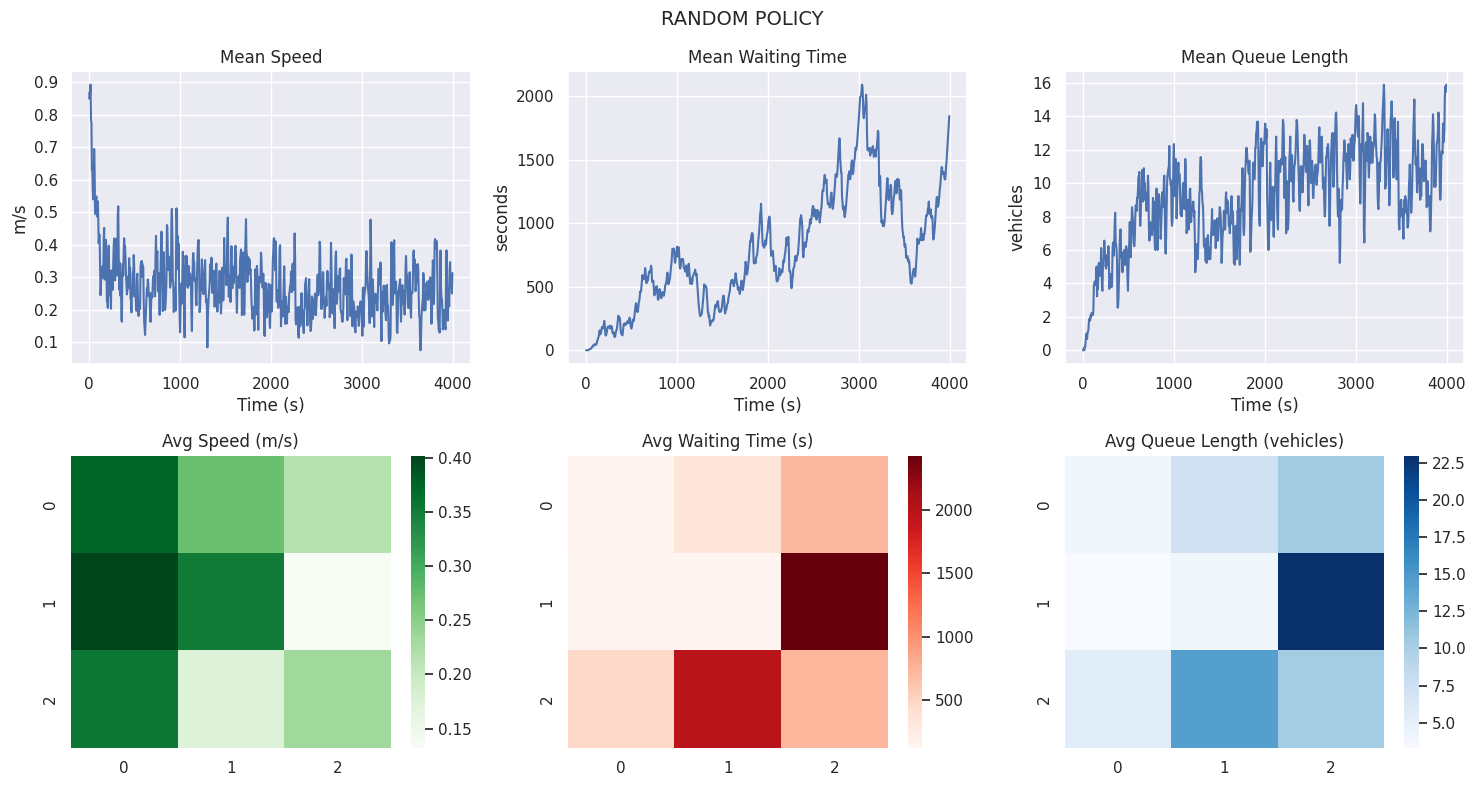


Fixed time policy score=-0.0723


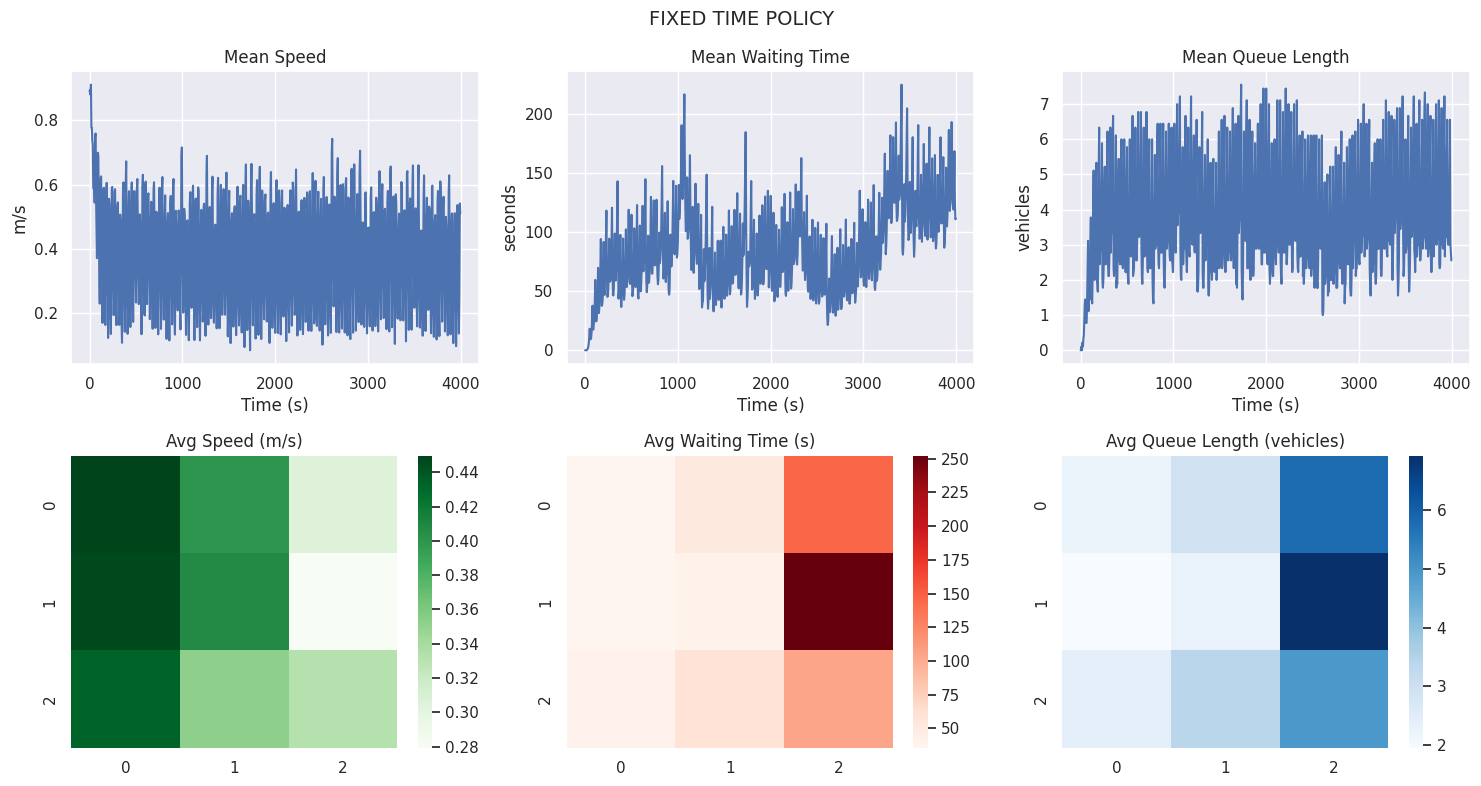



Training IMPALA
Iter: 1 | Reward: -235.590
Iter: 2 | Reward: -165.920
Iter: 3 | Reward: -293.767
Iter: 4 | Reward: -230.003
Iter: 5 | Reward: -190.040
Iter: 6 | Reward: -163.263
Iter: 7 | Reward: -142.227
Iter: 8 | Reward: -129.034
Iter: 9 | Reward: -118.436
Iter: 10 | Reward: -110.251
IMPALA score=-43.9332


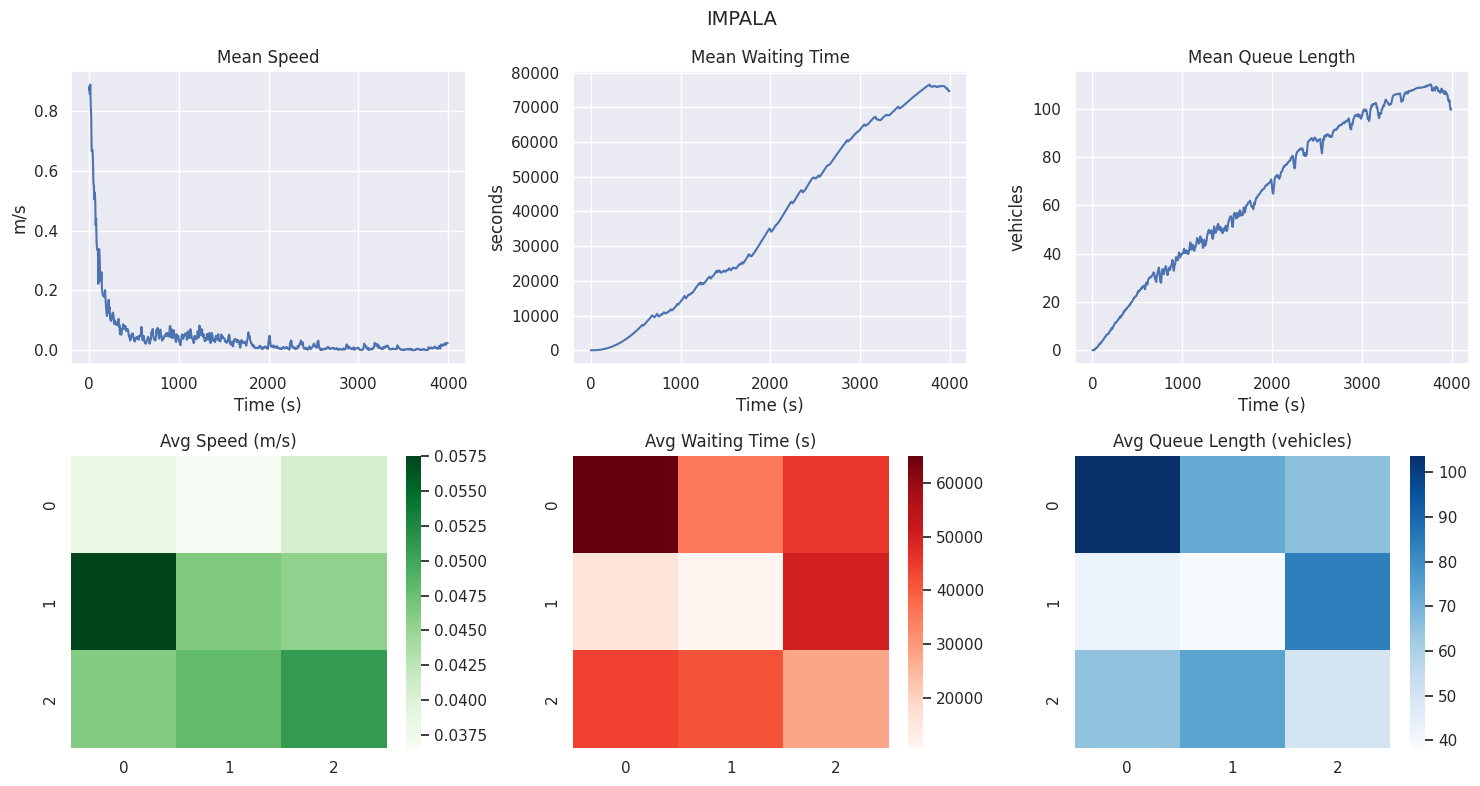



Training MAPPO
Iter: 1 | Reward: -50.790
Iter: 2 | Reward: -34.270
Iter: 3 | Reward: -26.250
Iter: 4 | Reward: -20.482
Iter: 5 | Reward: -16.920
Iter: 6 | Reward: -14.318
Iter: 7 | Reward: -12.693
Iter: 8 | Reward: -11.240
Iter: 9 | Reward: -10.026
Iter: 10 | Reward: -9.313
MAPPO score=0.6442


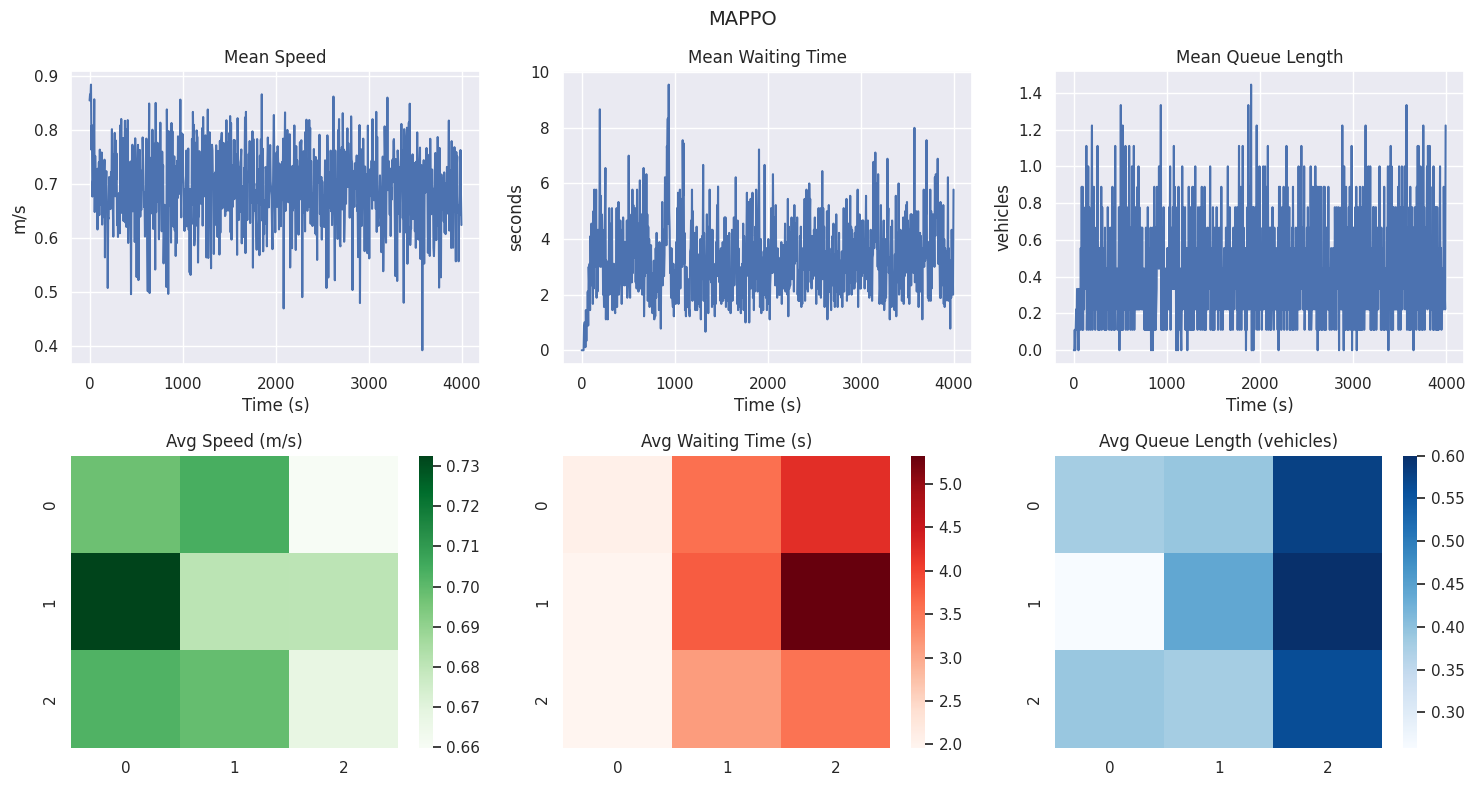

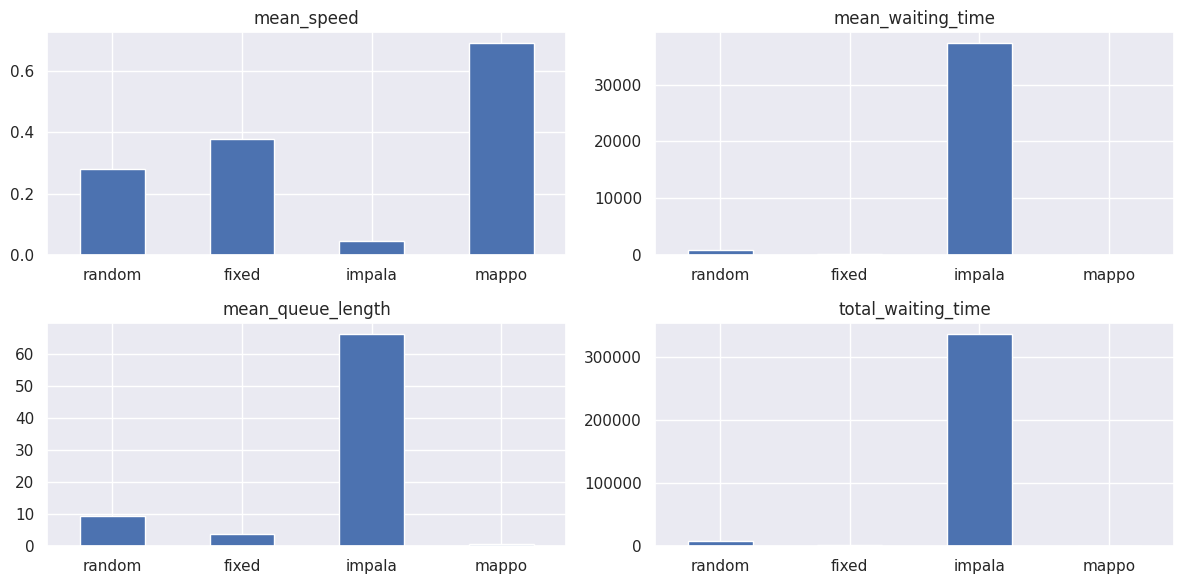

,mean_speed,mean_waiting_time,mean_queue_length,total_waiting_time
random,0.279335,784.649444,9.170417,7061.84500
fixed,0.378700,84.988750,3.660417,764.89875
impala,0.045582,37365.368889,66.134306,336288.32000
mappo,0.691687,3.284028,0.442361,29.55625


In [ ]:
# FINAL COMPARISON

results = {}
TRAIN_ITERS = 10

# ===== RANDOM =====
env = make_env(EVAL_SECONDS, parallel=True)
history, per_agent_history = run_episode(env, RandomPolicy())
summary = compute_summary(history)
score = compute_score(summary)
print(f"Random policy score={score:.4f}")
plot_metrics("RANDOM POLICY", history, per_agent_history, env)
results["random"] = history
env.close()


# ===== FIXED TIME =====
env = make_env(EVAL_SECONDS, parallel=True)
history, per_agent_history = run_episode(env, FixedTimePolicy(best_cycle))
summary = compute_summary(history)
score = compute_score(summary)
print(f"\nFixed time policy score={score:.4f}")
plot_metrics("FIXED TIME POLICY", history, per_agent_history, env)
results["fixed"] = history
env.close()


# ===== IMPALA =====
algo_name = "impala"
algo = build_algo(algo_name, best_impala)
print("\n")
train(algo, algo_name)

env = make_env(EVAL_SECONDS, parallel=True)
history, per_agent_history = run_episode(env, RLPolicy(algo))
summary = compute_summary(history)
score = compute_score(summary)
print(f"IMPALA score={score:.4f}")
plot_metrics("IMPALA", history, per_agent_history, env)
results["impala"] = history
env.close()
algo.stop()


# ===== MAPPO =====
algo_name = "mappo"
algo = build_algo(algo_name, best_mappo)
print("\n")
train(algo, algo_name)

env = make_env(EVAL_SECONDS, parallel=True)
history, per_agent_history = run_episode(env, RLPolicy(algo))
summary = compute_summary(history)
score = compute_score(summary)
print(f"MAPPO score={score:.4f}")
plot_metrics("MAPPO", history, per_agent_history, env)
results["mappo"] = history
env.close()
algo.stop()

ray.shutdown()

compare(results)